#Лабораторная работа № 8
#Бинарная классификация с использованием нейросети
**Цель работы**: изучить архитектуру и принцип работы нейронных сетей на примере решения задачи бинарной классификации.

Основные задачи:

• освоение работы с многослойным перцептроном (нейронной сетью прямого распространения)

• оценка эффективности модели на практическом примере решения задачи бинарной классификации

• изучение методов визуализации модели и оценки ее корректности

В этом примере мы используем набор данных о клиентах онлайн-доставки еды "Online Foods"

#1. Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, callbacks
import seaborn as sns
import matplotlib.pyplot as plt

#2. Загрузка и первичный анализ данных

In [2]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('onlinefoods.csv')
df.head()

Saving onlinefoods.csv to onlinefoods.csv


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,latitude,longitude,Pin code,Output,Feedback,Unnamed: 12
0,20,Female,Single,Student,No Income,Post Graduate,4,12.9766,77.5993,560001,Yes,Positive,Yes
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,12.9770,77.5773,560009,Yes,Positive,Yes
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,12.9551,77.6593,560017,Yes,Negative,Yes
3,22,Female,Single,Student,No Income,Graduate,6,12.9473,77.5616,560019,Yes,Positive,Yes
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,12.9850,77.5533,560010,Yes,Positive,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 388 entries, 0 to 387
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         388 non-null    int64  
 1   Gender                      388 non-null    object 
 2   Marital Status              388 non-null    object 
 3   Occupation                  388 non-null    object 
 4   Monthly Income              388 non-null    object 
 5   Educational Qualifications  388 non-null    object 
 6   Family size                 388 non-null    int64  
 7   latitude                    388 non-null    float64
 8   longitude                   388 non-null    float64
 9   Pin code                    388 non-null    int64  
 10  Output                      388 non-null    object 
 11  Feedback                    388 non-null    object 
 12  Unnamed: 12                 388 non-null    object 
dtypes: float64(2), int64(3), object(8)


#3. Извлечение последней строки датафрейма (практическое применение)

In [4]:
row_to_remove = df.iloc[387]
df = df.drop(df.index[387])

print("\nУдаленная строка (Series):")
print(row_to_remove)
print(f"Тип: {type(row_to_remove)}")


Удаленная строка (Series):
Age                                      23
Gender                                 Male
Marital Status                       Single
Occupation                          Student
Monthly Income                    No Income
Educational Qualifications    Post Graduate
Family size                               5
latitude                            12.8988
longitude                           77.5764
Pin code                             560078
Output                                  Yes
Feedback                           Positive
Unnamed: 12                             Yes
Name: 387, dtype: object
Тип: <class 'pandas.core.series.Series'>


#4.Предобработка данных

In [5]:
df = df.drop(columns=['Unnamed: 12', 'Feedback'], errors='ignore')

In [6]:
features = ['Age', 'Gender', 'Marital Status', 'Occupation',
            'Monthly Income', 'Educational Qualifications',
            'Family size', 'latitude', 'longitude']

X = df[features].copy()
y = df['Output'].copy()

# Преобразуем целевую переменную в бинарную (Yes=1, No=0)
y = y.map({'Yes': 1, 'No': 0})

In [7]:
print(X.isnull().sum())
print(y.isnull().sum())

Age                           0
Gender                        0
Marital Status                0
Occupation                    0
Monthly Income                0
Educational Qualifications    0
Family size                   0
latitude                      0
longitude                     0
dtype: int64
0


In [8]:
X = pd.get_dummies(X, columns=['Gender', 'Marital Status', 'Occupation','Monthly Income', 'Educational Qualifications'], drop_first=True)

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

#5. Масштабирование признаков

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#6. Построение модели с Keras API

In [11]:
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')
])

#7. Компиляция модели

In [12]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',keras.metrics.Precision(),keras.metrics.Recall()]
)

#8. Обучение модели с валидацией

In [13]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 6s 192ms/step - accuracy: 0.3887 - loss: 0.7837 - precision: 0.7846 - recall: 0.2713 - val_accuracy: 0.3871 - val_loss: 0.7064 - val_precision: 0.7692 - val_recall: 0.3846
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5911 - loss: 0.6777 - precision: 0.7806 - recall: 0.6436 - val_accuracy: 0.7903 - val_loss: 0.6282 - val_precision: 0.8421 - val_recall: 0.9231
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.6923 - loss: 0.6214 - precision: 0.7745 - recall: 0.8404 - val_accuracy: 0.8065 - val_loss: 0.5765 - val_precision: 0.8333 - val_recall: 0.9615
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.7733 - loss: 0.5820 - precision: 0.7895 - recall: 0.9574 - val_accuracy: 0.8065 - val_loss: 0.5369 - val_precision: 0.8333 - val_recall: 0.9615
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7571 - loss: 0.5718 - precision: 0.7712 - recall: 0.9681 - val_accuracy: 0.8387 - val_loss: 0.5049 - va

#9. Оценка модели на тестовых данных

In [14]:
test_loss, test_acc, test_prec, test_rec = model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Test Precision: {test_prec:.4f}")
print(f"Test Recall:    {test_rec:.4f}")

Test Accuracy:  0.7949
Test Precision: 0.7973
Test Recall:    0.9833


#10. Визуализация процесса обучения

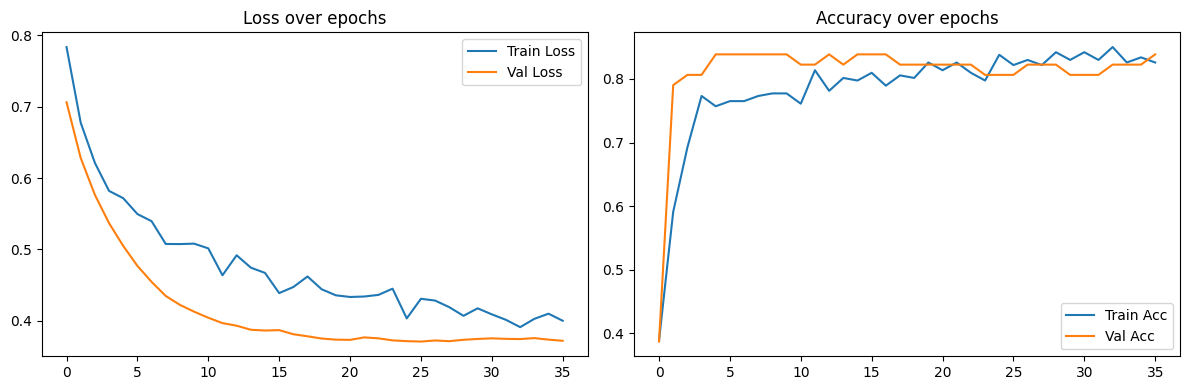

In [15]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss over epochs')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.legend()
plt.title('Accuracy over epochs')

plt.tight_layout()
plt.show()

#11. Предсказание для нового клиента


In [16]:
new_passenger = pd.DataFrame({
    'Age': [row_to_remove['Age']],
    'Family size': [row_to_remove['Family size']],
    'latitude': [row_to_remove['latitude']],
    'longitude': [row_to_remove['longitude']],
    'Gender_Male': [1 if row_to_remove['Gender'] == 'Male' else 0],
    'Marital Status_Single': [1 if row_to_remove['Marital Status'] == 'Single' else 0],
    'Occupation_Student': [1 if row_to_remove['Occupation'] == 'Student' else 0],
    'Monthly Income_No Income': [1 if row_to_remove['Monthly Income'] == 'No Income' else 0],
    'Educational Qualifications_Post Graduate':
        [1 if row_to_remove['Educational Qualifications'] == 'Post Graduate' else 0]
})

# Приводим столбцы к тому же порядку, что и при обучении
new_passenger = new_passenger.reindex(columns=X_train.columns, fill_value=0)

# Масштабируем
new_scaled = scaler.transform(new_passenger)

# Вероятность заказа (Output = Yes)
prob = model.predict(new_scaled)[0][0]
print(f"Вероятность заказа (Output=Yes): {prob:.2f}")
print(f"Предсказание: {'Yes' if prob > 0.5 else 'No'}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
Вероятность заказа (Output=Yes): 0.96
Предсказание: Yes
